In [61]:
# Import required libraries
%reset -f
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import matplotlib.ticker as ticker
import os

In [62]:
# Configuration for grid study comparison
grid_study_folder = '../40/grid_study'
exp_folder = '../40/exp/40_Re_300'
output_dir = '../Plots/grid_study'
pos = 3

# Files to compare
grid_files = {
    'coarse': 'coarse_pos3.csv',
    'medium': 'medium_pos3.csv',
    'fine': 'fine_pos3.csv'
}
exp_file = 'S_Pos03_Re300_B0001_T.csv'

# Z-heights for line plots (in meters)
z_min = 0.180
z_max = 0.236
z_step = 0.015

n_arrows = 14
# Add constant offsets to velocity components (set to 0 for no offset)
z_velocity_offset = 0.0   # Constant term to add to Z-velocity [m/s]

In [63]:
# Plot settings
file_type = 'aver'

if not os.path.exists(output_dir):
    os.makedirs(output_dir)

print(f"Grid study comparison for Position: {pos}")

Grid study comparison for Position: 3


In [64]:
# Define velocity variable names
if file_type == 'inst':
    vx = 'Velocity_0'
    vy = 'Velocity_1'
    vz = 'Velocity_2'
else:
    vx = 'av_u_0'
    vy = 'av_u_1'
    vz = 'av_u_2'

# Map column names to standard format
header_mapping = {
    'x': 'Points_0', 'x ': 'Points_0',
    'y': 'Points_1', 'y ': 'Points_1',
    'z': 'Points_2', 'z ': 'Points_2',
    'Vel_u': 'av_u_0', 'Vel_v': 'av_u_1', 'Vel_w': 'av_u_2',
    'Vel_mag': 'av_u_Magnitude'
}

# Load all grid study files
dataframes = {}
for label, filename in grid_files.items():
    file_path = f'{grid_study_folder}/{filename}'
    df_temp = pd.read_csv(file_path)
    df_temp = df_temp.rename(columns=header_mapping)
    df_temp[vz] = df_temp[vz] + z_velocity_offset
    df_temp['vel_cal'] = np.sqrt(df_temp['av_u_0']**2 + df_temp['av_u_2']**2)
    dataframes[label] = df_temp
    print(f"Loaded {label}: {df_temp.shape[0]} points")

# Load experimental data
exp_path = f'{exp_folder}/{exp_file}'
df_exp = pd.read_csv(exp_path)
df_exp = df_exp.rename(columns=header_mapping)
df_exp['vel_cal'] = np.sqrt(df_exp['av_u_0']**2 + df_exp['av_u_2']**2)
dataframes['experiment'] = df_exp
print(f"Loaded experiment: {df_exp.shape[0]} points")

print("\nAll files loaded successfully")

Loaded coarse: 43469 points
Loaded medium: 77721 points
Loaded fine: 310685 points
Loaded experiment: 38250 points

All files loaded successfully


In [65]:
# Print velocity statistics for all files
print("\nVelocity Statistics:")
for label, df_temp in dataframes.items():
    print(f"\n{label.upper()}:")
    print(f"  X-velocity max: {df_temp['av_u_0'].max():.4f} m/s")
    print(f"  Z-velocity max: {df_temp['av_u_2'].max():.4f} m/s")
    print(f"  Velocity magnitude max: {df_temp['vel_cal'].max():.4f} m/s")


Velocity Statistics:

COARSE:
  X-velocity max: 0.1132 m/s
  Z-velocity max: 0.5136 m/s
  Velocity magnitude max: 0.5229 m/s

MEDIUM:
  X-velocity max: 0.1033 m/s
  Z-velocity max: 0.4632 m/s
  Velocity magnitude max: 0.4644 m/s

FINE:
  X-velocity max: 0.1042 m/s
  Z-velocity max: 0.4609 m/s
  Velocity magnitude max: 0.4620 m/s

EXPERIMENT:
  X-velocity max: 0.2562 m/s
  Z-velocity max: 1.3267 m/s
  Velocity magnitude max: 1.3432 m/s


In [66]:
# Determine domain bounds from fine grid (most resolved)
df_fine = dataframes['fine']
x_min = df_fine['Points_0'].min()
x_max = df_fine['Points_0'].max()
y_min = df_fine['Points_1'].min()
y_max = df_fine['Points_1'].max()
z_min_domain = df_fine['Points_2'].min()
z_max_domain = df_fine['Points_2'].max()

# Calculate center and offset positions
y_center = (y_min + y_max) / 2
y_range = y_max - y_min
y_offset = y_center + 0.0025 * y_range  # 0.25% offset from center

print("DOMAIN INFO")
print(f"  X: [{x_min:.6f}, {x_max:.6f}] m")
print(f"  Y: [{y_min:.6f}, {y_max:.6f}] m")
print(f"  Z: [{z_min_domain:.6f}, {z_max_domain:.6f}] m")
print(f"\nY-coordinates for line plots:")
print(f"  Center: {y_center:.6f} m")
print(f"  Offset (0.25%): {y_offset:.6f} m")

DOMAIN INFO
  X: [0.960175, 1.039825] m
  Y: [0.993511, 1.022502] m
  Z: [1.138000, 1.202205] m

Y-coordinates for line plots:
  Center: 1.008007 m
  Offset (0.25%): 1.008079 m


In [67]:
# Extract data at y_center for all files at multiple z-heights
z_values = np.arange(z_min, z_max + 1e-12, z_step)
print(f"\nExtracting data at y = {y_center:.6f} m (center)")
print(f"Z-heights from {z_min*1000:.3f} mm to {z_max*1000:.3f} mm")
print(f"Step size: {z_step*1000:.3f} mm")
print(f"Total number of z-heights: {len(z_values)}")

# Store data for each file at each z-height
stored_data_center = {}

for label, df_temp in dataframes.items():
    stored_data_center[label] = []
    
    # Find the closest y-value to y_center in this dataset
    unique_y = df_temp['Points_1'].unique()
    closest_y = unique_y[np.argmin(np.abs(unique_y - y_center))]
    print(f"\n{label}: Using y = {closest_y:.6f} m (closest to center)")
    
    # Filter data at this y-plane
    df_y_slice = df_temp[df_temp['Points_1'] == closest_y].copy()
    print(f"  Found {len(df_y_slice)} points at this y-plane")
    
    for z_target in z_values:
        # Find the closest z-value to z_target
        if len(df_y_slice) > 0:
            unique_z = df_y_slice['Points_2'].unique()
            if len(unique_z) > 0:
                closest_z = unique_z[np.argmin(np.abs(unique_z - z_target))]
                
                # Filter data at this z-plane
                df_z_slice = df_y_slice[df_y_slice['Points_2'] == closest_z].copy()
                
                if len(df_z_slice) > 0:
                    df_z_slice = df_z_slice.sort_values('Points_0')
                    stored_data_center[label].append({
                        'z_target_mm': z_target * 1000,
                        'z_actual_mm': closest_z * 1000,
                        'x': df_z_slice['Points_0'].values,
                        'vel': df_z_slice['vel_cal'].values,
                    })
                    print(f"  z={z_target*1000:.1f} mm: {len(df_z_slice)} points")

print(f"\n\nData extraction complete!")
for label in stored_data_center:
    print(f"{label}: {len(stored_data_center[label])} z-heights extracted")


Extracting data at y = 1.008007 m (center)
Z-heights from 180.000 mm to 236.000 mm
Step size: 15.000 mm
Total number of z-heights: 4

coarse: Using y = 1.008070 m (closest to center)
  Found 161 points at this y-plane
  z=180.0 mm: 1 points
  z=195.0 mm: 1 points
  z=210.0 mm: 1 points
  z=225.0 mm: 1 points

medium: Using y = 1.008013 m (closest to center)
  Found 215 points at this y-plane
  z=180.0 mm: 1 points
  z=195.0 mm: 1 points
  z=210.0 mm: 1 points
  z=225.0 mm: 1 points

fine: Using y = 1.008025 m (closest to center)
  Found 430 points at this y-plane
  z=180.0 mm: 1 points
  z=195.0 mm: 1 points
  z=210.0 mm: 1 points
  z=225.0 mm: 1 points

experiment: Using y = -0.007500 m (closest to center)
  Found 38250 points at this y-plane
  z=180.0 mm: 225 points
  z=195.0 mm: 225 points
  z=210.0 mm: 225 points
  z=225.0 mm: 225 points


Data extraction complete!
coarse: 4 z-heights extracted
medium: 4 z-heights extracted
fine: 4 z-heights extracted
experiment: 4 z-heights extra

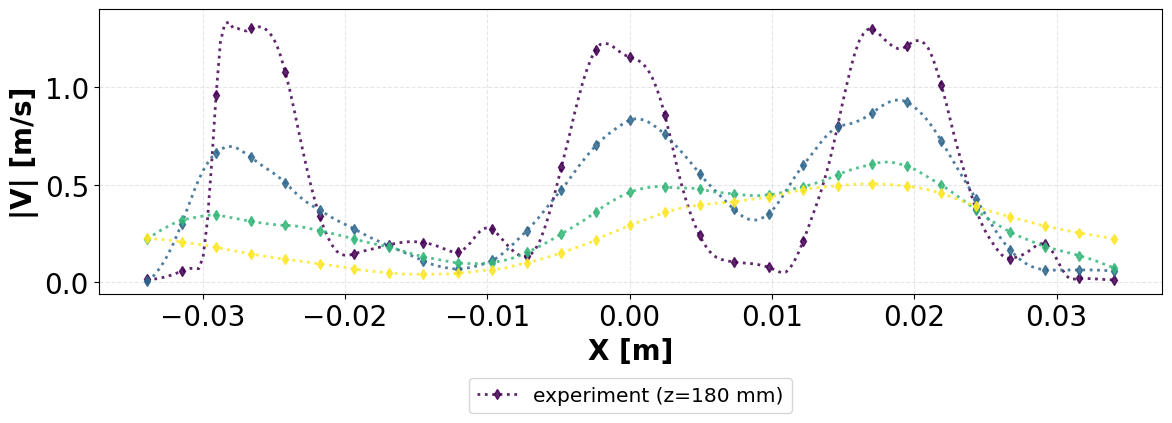


Saved comparison plot at y_center = 1.008007 m


In [68]:
# Create comparison plot for all files at center y-coordinate
fig, ax = plt.subplots(figsize=(12, 4.5))

# Define colors and styles for each file
plot_styles = {
    'coarse': {'linestyle': '--', 'linewidth': 2.0, 'marker': 'o', 'markersize': 4, 'markevery': 10},
    'medium': {'linestyle': '-.', 'linewidth': 2.0, 'marker': 's', 'markersize': 4, 'markevery': 10},
    'fine': {'linestyle': '-', 'linewidth': 2.5, 'marker': None, 'markersize': 0, 'markevery': 1},
    'experiment': {'linestyle': ':', 'linewidth': 2.0, 'marker': 'd', 'markersize': 5, 'markevery': 8}
}

colors_z = plt.cm.viridis(np.linspace(0, 1, len(z_values)))

# Plot each file at each z-height
for i, z_target in enumerate(z_values):
    for label in ['experiment']:
        if label in stored_data_center and i < len(stored_data_center[label]):
            data = stored_data_center[label][i]
            style = plot_styles[label]
            
            # Only show label for first z-height
            plot_label = f'{label} (z={data["z_target_mm"]:.0f} mm)' if i == 0 else None
            
            ax.plot(
                data['x'], data['vel'],
                label=plot_label,
                color=colors_z[i],
                linestyle=style['linestyle'],
                linewidth=style['linewidth'],
                marker=style['marker'] if style['marker'] else None,
                markersize=style['markersize'],
                markevery=style['markevery'],
                alpha=0.85,
                zorder=2
            )

ax.set_xlabel('X [m]', fontsize=20, fontweight='bold')
ax.set_ylabel('|V| [m/s]', fontsize=20, fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=20)
ax.legend(fontsize=14.5, loc='upper center', bbox_to_anchor=(0.5, -0.26), ncol=4, frameon=True)

plt.tight_layout()
plt.savefig(f'{output_dir}/Grid_Comparison_Center_Pos{pos}.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nSaved comparison plot at y_center = {y_center:.6f} m")

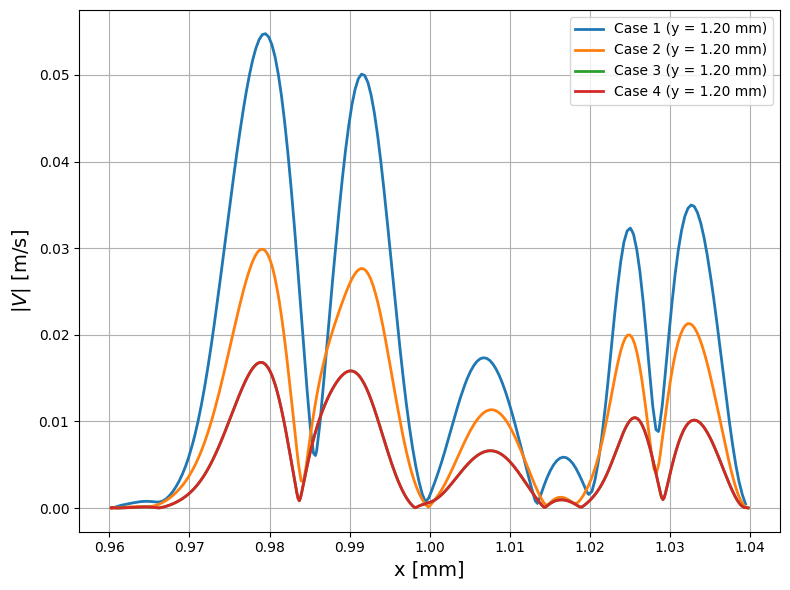

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# File paths
# ------------------------------------------------------------------
files = [
    "../40/grid_study/coarse_pos3.csv",
    "../40/grid_study/medium_pos3.csv",
    "../40/grid_study/fine_pos3.csv",
    "../40/grid_study/fine_pos3.csv"
]

labels = [
    "Case 1",
    "Case 2",
    "Case 3",
    "Case 4"
]

# ------------------------------------------------------------------
# Target y location (mm)
# ------------------------------------------------------------------
target_y = 115.0

plt.figure(figsize=(8,6))

for file, label in zip(files, labels):

    # Read file
    df = pd.read_csv(file)

    # Velocity magnitude
    df["Vmag"] = np.sqrt(df["av_u_0"]**2 + df["av_u_2"]**2)

    # Find the y-plane closest to 185 mm
    y_closest = df["Points_2"].iloc[(df["Points_2"] - target_y).abs().argmin()]

    # Extract that plane
    plane = df[df["Points_2"] == y_closest].copy()

    # Sort by x for a smooth line
 #   plane = plane.sort_values("Points_0")

    # Plot
    plt.plot(
        plane["Points_0"],
        plane["Vmag"],
        linewidth=2,
        label=f"{label} (y = {y_closest:.2f} mm)"
    )

plt.xlabel("x [mm]", fontsize=14)
plt.ylabel(r"$|V|$ [m/s]", fontsize=14)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

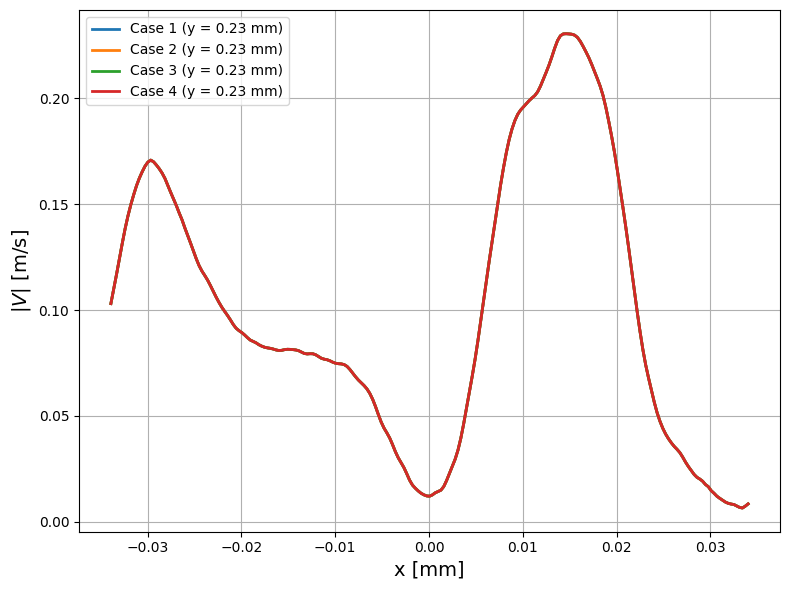

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# File paths
# ------------------------------------------------------------------
files = [
    "../40/grid_study/S_Pos03_Re100_B0001_T.csv",
    "../40/grid_study/S_Pos03_Re100_B0001_T.csv",
    "../40/grid_study/S_Pos03_Re100_B0001_T.csv",
    "../40/grid_study/S_Pos03_Re100_B0001_T.csv"
]

labels = [
    "Case 1",
    "Case 2",
    "Case 3",
    "Case 4"
]

plt.figure(figsize=(8,6))

x_ref = None

for i, (file, label) in enumerate(zip(files, labels)):

    # Read file
    df = pd.read_csv(file)

    # Velocity magnitude
    df["Vmag"] = np.sqrt(df["av_u_0"]**2 + df["av_u_2"]**2)

    # Target y = 5 mm above minimum
    target_y = df["Points_2"].min() + 5.0

    # Find nearest y-plane
    y_closest = df.loc[(df["Points_2"] - target_y).abs().idxmin(), "Points_2"]

    # Extract plane
    plane = df[df["Points_2"] == y_closest].copy()

    # Sort by x
    plane = plane.sort_values("Points_0")

    # Save x from Case 3
    if i == 2:
        x_ref = plane["Points_0"].values

    # Use the same x for Case 4
    if i == 3 and x_ref is not None:
        plane["Points_0"] = x_ref

    # Plot
    plt.plot(
        plane["Points_0"],
        plane["Vmag"],
        linewidth=2,
        label=f"{label} (y = {y_closest:.2f} mm)"
    )

plt.xlabel("x [mm]", fontsize=14)
plt.ylabel(r"$|V|$ [m/s]", fontsize=14)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()